# ACML Assignment 2: Convolutional Autoencoders

**Authors:** Simon Delecluse, Francesco Suriano

## Abstract
In this work we build a convolutional autoencoder (CAE) in PyTorch and train it to reconstruct CIFAR-10 images. We start from the architecture given in the assignment, which compresses a 32x32x3 image into a latent code of 8x8x16 = 1024 values and reaches a test MSE of 0.00449.
Then we try three other types of autoencoder (wider layers, a different number of conv + pool stages, and a two path encoder with two kinds of filters), each with a latent of 512 and 2048 values. A bigger latent always gives a lower error, but how the latent is built matters as much as its size: with 2048 values, 4x4 latents stay blurry while 8x8 and 16x16 latents keep most details. The best model is the two path autoencoder with a 2048 latent (test MSE 0.00115).
Finally we use this model to colourise grayscale images: we freeze its decoder and train only a new encoder that reads the gray image, and then we also train the whole network. Both beat simply copying the gray image in the three channels (0.00607 and 0.00592 against 0.00659), but the colours stay pale and brownish, which is the expected effect of the MSE loss when the colour of an object is uncertain.

## Imports and hyperparameters
Here we import only the libraries that we use in the notebook.

In [24]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, TensorDataset

Here we set the seed for reproducibility and the hyperparameters of the training. We use the GPU when there is one, and we save every trained model in `results_report` so we don't have to train it again.

In [25]:
SEED = 456
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128
LR = 2e-3
EPOCHS = 30      # max epochs, early stopping usually ends sooner
PATIENCE = 5     # stop after 5 epochs without improvement on validation

# trained models are saved here, so running the notebook again doesn't retrain them
RESULTS_DIR = "results_report"
os.makedirs(RESULTS_DIR, exist_ok=True)

torch.manual_seed(SEED)
print(DEVICE)

cuda


## Data
CIFAR-10 has 60 000 colour images of 32x32x3. We merge the official train and test sets, shuffle them and split them again **80 / 10 / 10** (48k train, 6k validation, 6k test). We need a validation set for early stopping and to compare the models, while the test set is used only to report the final error.

We scale the pixels from [0, 255] to **[0, 1]**, the same range as the sigmoid at the end of the decoder. Since it's an autoencoder, the target of every image is the image itself.

In [26]:
train_set = torchvision.datasets.CIFAR10(root="./data", train=True, download=True)
test_set = torchvision.datasets.CIFAR10(root="./data", train=False, download=True)

# (N, H, W, C) uint8 -> (N, C, H, W) float in [0, 1]
x = np.concatenate([train_set.data, test_set.data])
x = torch.from_numpy(x).permute(0, 3, 1, 2).float() / 255

# shuffle and split 80 / 10 / 10
x = x[torch.randperm(len(x), generator=torch.Generator().manual_seed(SEED))]
n_train, n_val = int(0.8 * len(x)), int(0.1 * len(x))
x_train, x_val, x_test = x[:n_train], x[n_train:n_train + n_val], x[n_train + n_val:]


def make_loader(inputs, targets, shuffle=False):
    return DataLoader(TensorDataset(inputs, targets), batch_size=BATCH_SIZE, shuffle=shuffle)


# for an autoencoder the target is the input itself
train_loader = make_loader(x_train, x_train, shuffle=True)
val_loader = make_loader(x_val, x_val)
test_loader = make_loader(x_test, x_test)

print("train", tuple(x_train.shape), "| val", tuple(x_val.shape), "| test", tuple(x_test.shape))

train (48000, 3, 32, 32) | val (6000, 3, 32, 32) | test (6000, 3, 32, 32)


## Helpers
Here we define the functions that we use in the rest of the notebook:
- `evaluate` computes the average MSE of a model over a loader.
- `train` trains the model with **Adam** and the **MSE** loss. After every epoch we compute the validation loss, and if it doesn't improve for `PATIENCE` epochs we stop and go back to the weights of the best epoch (**early stopping**). Frozen layers are left out of the optimizer.
- `train_or_load` saves every trained model, so when we run the notebook again we just load it instead of training it again.
- `predict`, `count_params` and `latent_size` are small utilities, while `plot_history` and `show_images` make the learning curves and the image grids.

In [27]:
loss_fn = nn.MSELoss()


def evaluate(model, loader):
    """average MSE over a loader"""
    model.eval()
    total = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            total += loss_fn(model(xb), yb).item() * len(xb)
    return total / len(loader.dataset)


def train(model, train_loader, val_loader, lr=LR):
    """Adam + MSE with early stopping, returns the train and val loss of every epoch"""
    params = [p for p in model.parameters() if p.requires_grad]   # frozen layers are left out
    optimizer = torch.optim.Adam(params, lr=lr)
    history = {"train": [], "val": []}
    best_val, best_weights, bad_epochs = float("inf"), None, 0

    for epoch in range(EPOCHS):
        model.train()
        total = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)

        history["train"].append(total / len(train_loader.dataset))
        history["val"].append(evaluate(model, val_loader))
        print(f"epoch {epoch + 1:2d}  train {history['train'][-1]:.5f}  val {history['val'][-1]:.5f}")

        if history["val"][-1] < best_val:
            best_val, bad_epochs = history["val"][-1], 0
            best_weights = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs == PATIENCE:
                print("early stopping")
                break

    model.load_state_dict(best_weights)
    return history


def train_or_load(name, model, train_loader, val_loader, lr=LR):
    """train the model and save it, or load it if it is already saved"""
    path = os.path.join(RESULTS_DIR, name.replace(" ", "_") + ".pt")
    model.to(DEVICE)
    if os.path.exists(path):
        saved = torch.load(path, map_location=DEVICE)
        model.load_state_dict(saved["weights"])
        print("loaded", path)
        return saved["history"]
    history = train(model, train_loader, val_loader, lr)
    torch.save({"weights": model.state_dict(), "history": history}, path)
    return history


def predict(model, x):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(xb.to(DEVICE)).cpu() for xb in x.split(500)])


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def latent_size(model, in_ch=3):
    """number of values in the latent code of one image"""
    dummy = torch.zeros(1, in_ch, 32, 32, device=next(model.parameters()).device)
    with torch.no_grad():
        return model.encoder(dummy).numel()


def plot_history(history, title):
    epochs = range(1, len(history["train"]) + 1)
    plt.figure(figsize=(6, 3.5))
    plt.plot(epochs, history["train"], label="train")
    plt.plot(epochs, history["val"], label="validation")
    plt.xlabel("epoch")
    plt.ylabel("MSE")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()


def show_images(rows, n=8, title=""):
    """rows: {label: images}, one row of n images per label (gray or RGB)"""
    fig, axes = plt.subplots(len(rows), n, figsize=(1.5 * n, 1.6 * len(rows)))
    for r, (label, images) in enumerate(rows.items()):
        for i in range(n):
            img = images[i].clamp(0, 1)
            if img.shape[0] == 1:
                axes[r, i].imshow(img[0], cmap="gray", vmin=0, vmax=1)
            else:
                axes[r, i].imshow(img.permute(1, 2, 0))
            axes[r, i].axis("off")
        axes[r, 0].set_title(label, loc="left", fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## Baseline autoencoder
We build the architecture from the assignment, with all convs 3x3, stride 1, "same" padding and ReLU activations:

`Conv (8) -> MaxPool 2x2 -> Conv (12) -> MaxPool 2x2 -> Conv (16) -> Upsample 2x2 -> Conv (12) -> Upsample 2x2 -> Conv (3)`

- The **encoder** (conv, pool, conv, pool, conv) compresses the 32x32x3 image into the **latent code**.
- The **decoder** (upsample, conv, upsample, conv) rebuilds the image from that code. Upsampling repeats each pixel into a 2x2 block.
- Max pooling has stride 2, so every pool halves the image: 32 -> 16 -> 8. The convs keep the size thanks to the padding.
- The last layer is a **sigmoid**, so the output is in [0, 1] like the input.

We wrap encoder and decoder in the small class `AE`, so that later we can swap them, for example to freeze the decoder in the colourisation part. The model is very small, with only 4911 parameters.

In [28]:
class AE(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x):
        return self.decoder(self.encoder(x))


torch.manual_seed(SEED)
baseline = AE(
    encoder=nn.Sequential(
        nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(),       # 32x32x8
        nn.MaxPool2d(2),                                # 16x16x8
        nn.Conv2d(8, 12, 3, padding=1), nn.ReLU(),      # 16x16x12
        nn.MaxPool2d(2),                                # 8x8x12
        nn.Conv2d(12, 16, 3, padding=1), nn.ReLU(),     # 8x8x16 = latent
    ),
    decoder=nn.Sequential(
        nn.Upsample(scale_factor=2),                    # 16x16x16
        nn.Conv2d(16, 12, 3, padding=1), nn.ReLU(),     # 16x16x12
        nn.Upsample(scale_factor=2),                    # 32x32x12
        nn.Conv2d(12, 3, 3, padding=1), nn.Sigmoid(),   # 32x32x3
    ),
)
print(baseline)
print("parameters:", count_params(baseline))

AE(
  (encoder): Sequential(
    (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(12, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
  )
  (decoder): Sequential(
    (0): Upsample(scale_factor=2.0, mode='nearest')
    (1): Conv2d(16, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): ReLU()
    (3): Upsample(scale_factor=2.0, mode='nearest')
    (4): Conv2d(12, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): Sigmoid()
  )
)
parameters: 4911


### Latent space size
The output width of a conv or pooling layer is $\frac{W-K+2P}{S}+1$, with input width $W$, kernel $K$, padding $P$ and stride $S$.

| layer | W | K | P | S | channels | output | values |
|---|---|---|---|---|---|---|---|
| conv 3x3 | 32 | 3 | 1 | 1 | 8 | 32x32x8 | 8192 |
| max pool | 32 | 2 | 0 | 2 | 8 | 16x16x8 | 2048 |
| conv 3x3 | 16 | 3 | 1 | 1 | 12 | 16x16x12 | 3072 |
| max pool | 16 | 2 | 0 | 2 | 12 | 8x8x12 | 768 |
| conv 3x3 | 8 | 3 | 1 | 1 | 16 | 8x8x16 | **1024** |

So the latent code has **8x8x16 = 1024** values, against 32x32x3 = 3072 of the input: a compression by a factor of 3. In the cell below we pass an empty image through the encoder to check it on the model, and we get the same size.

In [29]:
with torch.no_grad():
    z = baseline.encoder(torch.zeros(1, 3, 32, 32))
print("latent shape:", tuple(z.shape[1:]), "->", z.numel(), "values")

latent shape: (16, 8, 8) -> 1024 values


### Training and test
We train the baseline, plot the train and validation loss over the epochs, and look at the test MSE and at some reconstructed test images.

loaded results_report\baseline_1024.pt


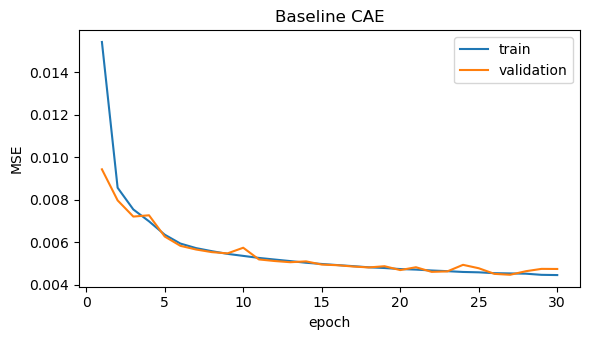

test MSE: 0.00449


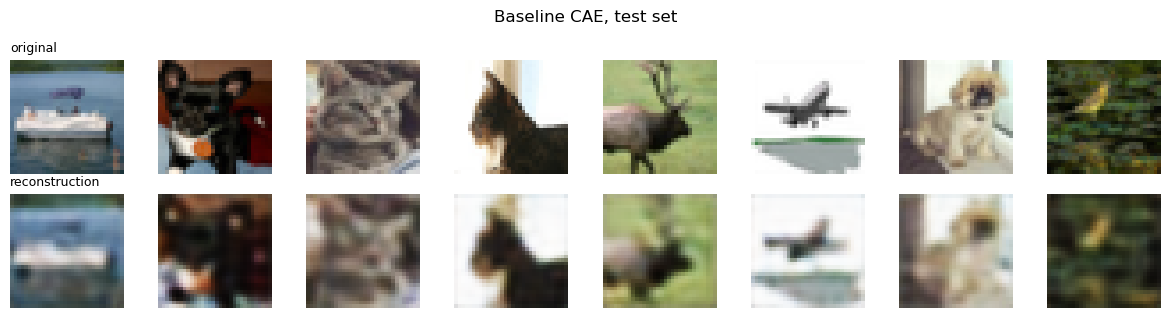

In [30]:
history = train_or_load("baseline 1024", baseline, train_loader, val_loader)
plot_history(history, "Baseline CAE")
print("test MSE:", round(evaluate(baseline, test_loader), 5))
show_images({"original": x_test, "reconstruction": predict(baseline, x_test[:8])}, title="Baseline CAE, test set")

**Discussion.** The train and validation curves stay very close to each other, so the model doesn't overfit. This makes sense since it has only about 5000 parameters for 48 000 images. Most of the improvement happens in the first 5 epochs, after that the loss goes down slowly. Early stopping never stopped the training: the best validation epoch is 27 of 30, so with more epochs the model could still improve a little.

The test MSE (0.00449) is almost the same as the validation one (0.00447), so the result also holds on unseen images. From the reconstructions we can see that the model keeps the shapes and the main colours, but the images are blurry and small details are lost (the antlers of the deer, the face of the dog). This is the price of squeezing the image into 1024 values.

## Other architectures
We try three types of autoencoder, each with **two latent sizes, 512 and 2048** (the baseline sits in the middle with 1024). We set the latent size with the number of channels of the last encoder conv.

- **Wide**: same layout as the baseline but with 32 and 64 channels instead of 8 and 12. More capacity, same 8x8 latent.
- **Number of conv + pool stages**: 1 stage (latent 16x16) and 3 stages (latent 4x4). The latent size is the same, but it's traded between spatial resolution and channels.
- **Two path**: two encoders side by side on the same image, one with 3x3 filters and max pooling, one with 5x5 filters and stride 2. We stack their outputs at 8x8 and merge them into the latent code. The idea is that small filters keep local details while big filters see more context.

All decoders mirror the encoder with upsampling + conv. In the cell below we define the building blocks and the list of experiments.

In [31]:
def conv_pool_encoder(channels, latent_ch, in_ch=3):
    """one conv + max pool per stage, then a conv to the latent channels"""
    layers = []
    for c in channels:
        layers += [nn.Conv2d(in_ch, c, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]
        in_ch = c
    layers += [nn.Conv2d(in_ch, latent_ch, 3, padding=1), nn.ReLU()]
    return nn.Sequential(*layers)


def upsample_decoder(channels, latent_ch):
    """mirror of the encoder: upsample + conv per stage, sigmoid at the end"""
    outs = list(reversed(channels))[:-1] + [3]   # e.g. (8, 12) -> (12, 3) like the baseline
    layers = []
    in_ch = latent_ch
    for c in outs:
        layers += [nn.Upsample(scale_factor=2), nn.Conv2d(in_ch, c, 3, padding=1), nn.ReLU()]
        in_ch = c
    layers[-1] = nn.Sigmoid()
    return nn.Sequential(*layers)


class TwoPathEncoder(nn.Module):
    def __init__(self, latent_ch, in_ch=3):
        super().__init__()
        # small 3x3 filters and max pool, keeps local detail
        self.small = nn.Sequential(
            nn.Conv2d(in_ch, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 16x16
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),      # 8x8
        )
        # bigger 5x5 filters with stride 2, sees more context
        self.big = nn.Sequential(
            nn.Conv2d(in_ch, 16, 5, stride=2, padding=2), nn.ReLU(),          # 16x16
            nn.Conv2d(16, 32, 5, stride=2, padding=2), nn.ReLU(),             # 8x8
        )
        self.merge = nn.Sequential(nn.Conv2d(64, latent_ch, 3, padding=1), nn.ReLU())

    def forward(self, x):
        return self.merge(torch.cat([self.small(x), self.big(x)], dim=1))


STAGES = {
    "baseline": (8, 12),
    "wide": (32, 64),
    "1 stage": (8,),
    "3 stages": (8, 12, 16),
}


def build(kind, latent_ch, in_ch=3):
    if kind == "two path":
        return AE(TwoPathEncoder(latent_ch, in_ch), upsample_decoder((16, 32), latent_ch))
    channels = STAGES[kind]
    return AE(conv_pool_encoder(channels, latent_ch, in_ch), upsample_decoder(channels, latent_ch))


# (type, latent channels), chosen so that every type gets a 512 and a 2048 latent
EXPERIMENTS = [
    ("baseline", 16),                       # 8x8x16 = 1024, already trained above
    ("wide", 8), ("wide", 32),              # 8x8
    ("1 stage", 2), ("1 stage", 8),         # 16x16
    ("3 stages", 32), ("3 stages", 128),    # 4x4
    ("two path", 8), ("two path", 32),      # 8x8
]

Here we train (or load) every model of the list with the same seed and the same training budget, and we collect latent size, number of parameters, validation and test MSE in a table.

In [32]:
rows, models, histories = [], {}, {}
for kind, latent_ch in EXPERIMENTS:
    torch.manual_seed(SEED)
    model = build(kind, latent_ch)
    name = f"{kind} {latent_size(model)}"
    print("---", name)
    histories[name] = train_or_load(name, model, train_loader, val_loader)
    models[name] = model
    rows.append({
        "name": name,
        "type": kind,
        "latent channels": latent_ch,
        "latent size": latent_size(model),
        "params": count_params(model),
        "epochs": len(histories[name]["val"]),
        "val MSE": min(histories[name]["val"]),
        "test MSE": evaluate(model, test_loader),
    })

results = pd.DataFrame(rows).set_index("name")
results.style.format({"val MSE": "{:.5f}", "test MSE": "{:.5f}"})

--- baseline 1024
loaded results_report\baseline_1024.pt
--- wide 512
loaded results_report\wide_512.pt
--- wide 2048
loaded results_report\wide_2048.pt
--- 1 stage 512
loaded results_report\1_stage_512.pt
--- 1 stage 2048
loaded results_report\1_stage_2048.pt
--- 3 stages 512
loaded results_report\3_stages_512.pt
--- 3 stages 2048
loaded results_report\3_stages_2048.pt
--- two path 512
loaded results_report\two_path_512.pt
--- two path 2048
loaded results_report\two_path_2048.pt


,type,latent channels,latent size,params,epochs,val MSE,test MSE
name,,,,,,,
baseline 1024,baseline,16,1024,4911,30,0.00447,0.00449
wide 512,wide,8,512,30411,30,0.00242,0.00243
wide 2048,wide,32,2048,58083,30,0.00166,0.00167
1 stage 512,1 stage,2,512,427,30,0.00890,0.00880
1 stage 2048,1 stage,8,2048,1027,30,0.00170,0.00173
3 stages 512,3 stages,32,512,14175,30,0.00890,0.00893
3 stages 2048,3 stages,128,2048,41919,30,0.00783,0.00787
two path 512,two path,8,512,26955,26,0.00222,0.00223
two path 2048,two path,32,2048,47715,30,0.00113,0.00115


We plot the test MSE against the latent size, with one line per type of autoencoder. Then we plot the validation curves of all models and we compare their reconstructions on the same test images.

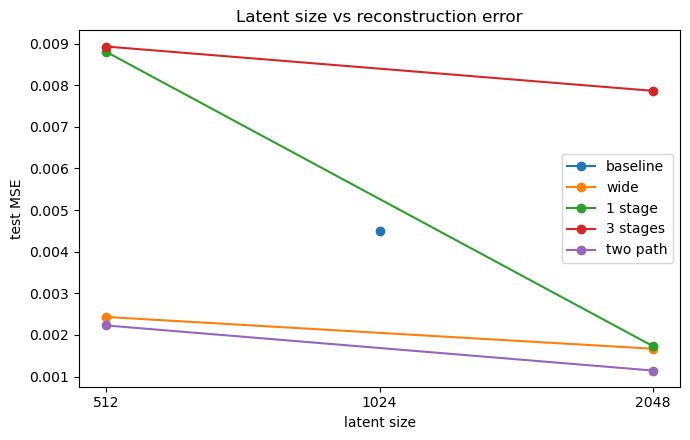

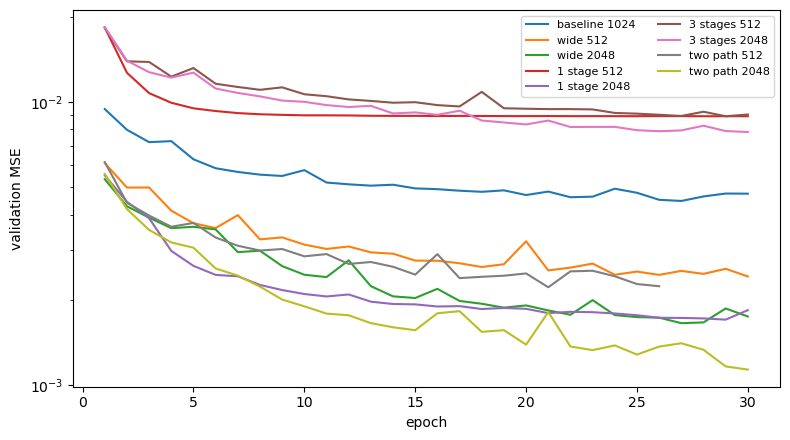

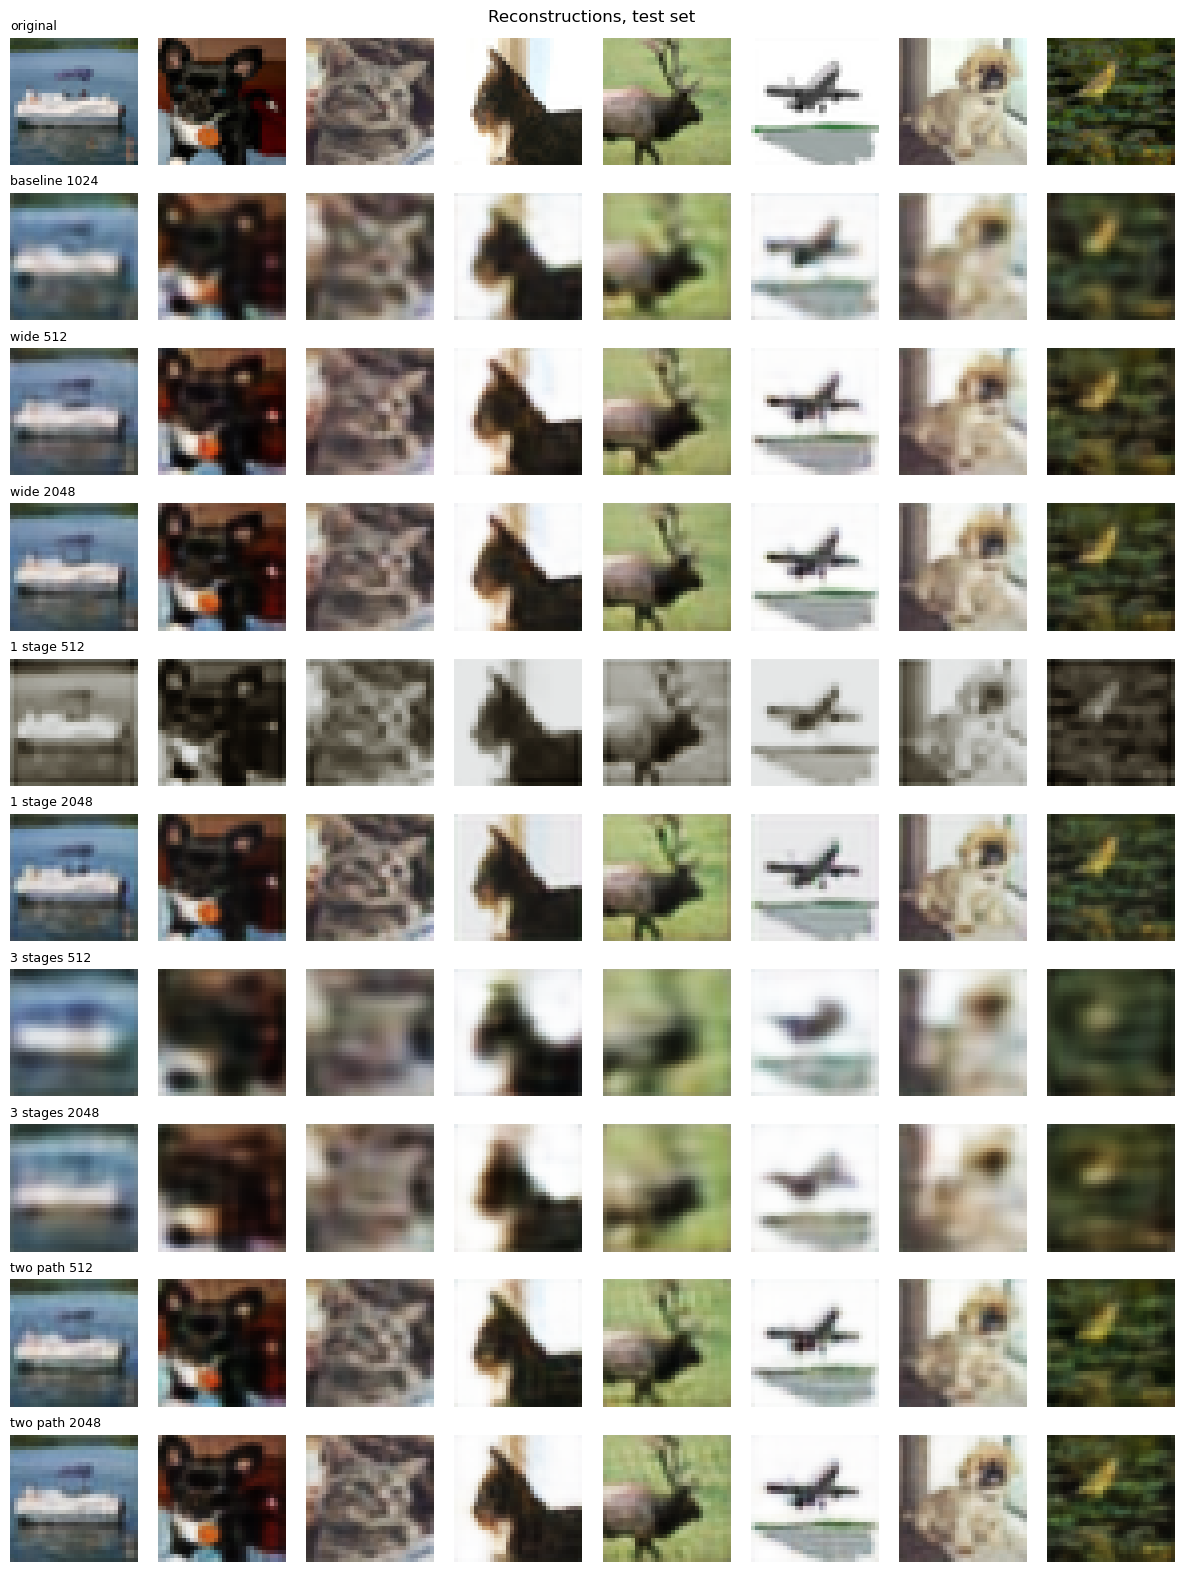

In [33]:
# latent size vs test error, one line per type
plt.figure(figsize=(7, 4.5))
for kind, df in results.groupby("type", sort=False):
    plt.plot(df["latent size"], df["test MSE"], "o-", label=kind)
plt.xscale("log", base=2)
plt.xticks([512, 1024, 2048], ["512", "1024", "2048"])
plt.xlabel("latent size")
plt.ylabel("test MSE")
plt.title("Latent size vs reconstruction error")
plt.legend()
plt.tight_layout()
plt.show()

# validation curves of all models
plt.figure(figsize=(8, 4.5))
for name, h in histories.items():
    plt.plot(range(1, len(h["val"]) + 1), h["val"], label=name)
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("validation MSE")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

show_images({"original": x_test[:8], **{name: predict(m, x_test[:8]) for name, m in models.items()}},
            title="Reconstructions, test set")

**Discussion.** The plot shows that, for every type of autoencoder, the 2048 latent gives a lower error than the 512 one: more values in the latent means less information is lost. But the latent size alone doesn't explain the results:
- **3 stages** is the worst model even with 2048 values (0.00787, worse than the baseline with 1024). A 4x4 latent has too little spatial resolution, so the reconstructions are very blurry. More channels can't give back where things are in the image.
- **1 stage** shows the opposite. With 2048 values (16x16x8) it gets 0.00173 with only 1027 parameters, almost as good as the wide model with 58k parameters. With 512 values, though, it has only 2 channels, and the reconstructions lose almost all their colour: the 2 channels are used for brightness, which is what matters most for the MSE.
- **Wide** improves a lot over the baseline (0.00243 and 0.00167), so the capacity of the encoder and decoder also matters, not only the latent.
- **Two path** is the best for both sizes, and **two path 2048** is the best model overall (0.00115). Its reconstructions are the sharpest ones.

Most models used all 30 epochs, so they hadn't fully converged. Since every model had the same budget the comparison is still fair, but the absolute errors could go a bit lower with longer training.

## Colourisation: grayscale -> RGB
The input is now a 1-channel grayscale image ($0.299R + 0.587G + 0.114B$) and the target is still the colour image.

We take the RGB autoencoder with the **lowest test MSE** among the ones we tried (two path 2048) and **freeze its decoder**: it already knows how to turn a latent code into a colour image. Then we train only a new encoder of the same type that reads the grayscale image. The encoder has to learn to map the gray image into the same latent space the decoder was trained on.

As a reference point we use the MSE of copying the gray value into all three channels, which is a "colourisation" without any colour.

In the cell below we make the grayscale versions of the three sets and pick the best model.

In [34]:
def to_gray(x):
    weights = torch.tensor([0.299, 0.587, 0.114]).view(1, 3, 1, 1)
    return (x * weights).sum(dim=1, keepdim=True)


g_train, g_val, g_test = to_gray(x_train), to_gray(x_val), to_gray(x_test)
gray_train_loader = make_loader(g_train, x_train, shuffle=True)
gray_val_loader = make_loader(g_val, x_val)
gray_test_loader = make_loader(g_test, x_test)

best_name = results["test MSE"].idxmin()
best_kind = results.loc[best_name, "type"]
best_latent = int(results.loc[best_name, "latent channels"])
print("best RGB autoencoder:", best_name)

best RGB autoencoder: two path 2048


Here we build the new encoder for 1-channel input, attach the decoder of the best RGB model and freeze it. We then train only the encoder, and at the end we check that the decoder weights didn't change.

trainable params (encoder): 36512 | total: 46627
loaded results_report\gray_frozen_decoder.pt


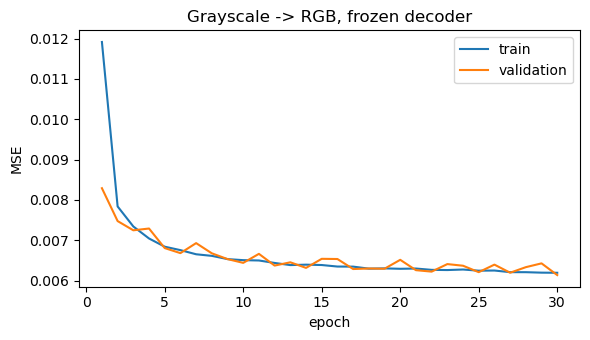

decoder unchanged: True


In [35]:
# new encoder for 1-channel input, decoder taken from the best RGB model and frozen
torch.manual_seed(SEED)
gray_model = build(best_kind, best_latent, in_ch=1)
gray_model.decoder = models[best_name].decoder
for p in gray_model.decoder.parameters():
    p.requires_grad = False
decoder_before = [p.clone() for p in gray_model.decoder.parameters()]

print("trainable params (encoder):", count_params(gray_model.encoder), "| total:", count_params(gray_model))

gray_history = train_or_load("gray frozen decoder", gray_model, gray_train_loader, gray_val_loader)
plot_history(gray_history, "Grayscale -> RGB, frozen decoder")
print("decoder unchanged:", all(torch.equal(a, b) for a, b in zip(decoder_before, gray_model.decoder.parameters())))

### Everything trainable
Now we start from the model above (trained encoder + RGB decoder) and unfreeze the decoder too, so we train the whole network on grayscale input. The decoder can now adapt to what the gray encoder produces, instead of only to latents of colour images. We use a learning rate 10 times lower because the weights already start from a good point.

We make a new copy of the model above, so the frozen version and the RGB autoencoder are not changed, and we train all its weights.

trainable params: 46627
loaded results_report\gray_full_training.pt


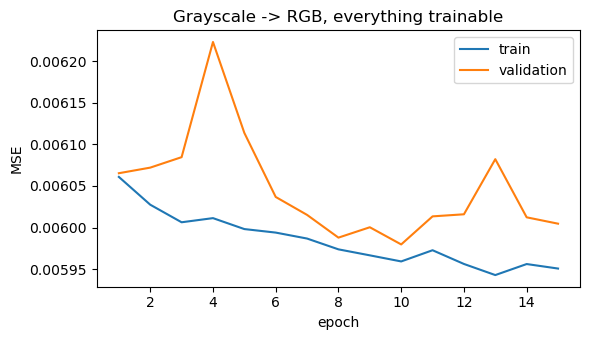

In [39]:
# a new copy of the model above, so the frozen version and the RGB autoencoder are not changed
torch.manual_seed(SEED)
full_model = build(best_kind, best_latent, in_ch=1)
full_model.load_state_dict(gray_model.state_dict())
print("trainable params:", count_params(full_model))

full_history = train_or_load("gray full training", full_model, gray_train_loader, gray_val_loader, lr=LR/10)
plot_history(full_history, "Grayscale -> RGB, everything trainable")

We compare the test MSE of the two colourisation models with the gray copy, and we look at the same test images for both.

gray copied to RGB (no colour):    0.00659
gray -> RGB, frozen decoder:       0.00607
gray -> RGB, everything trainable: 0.00592


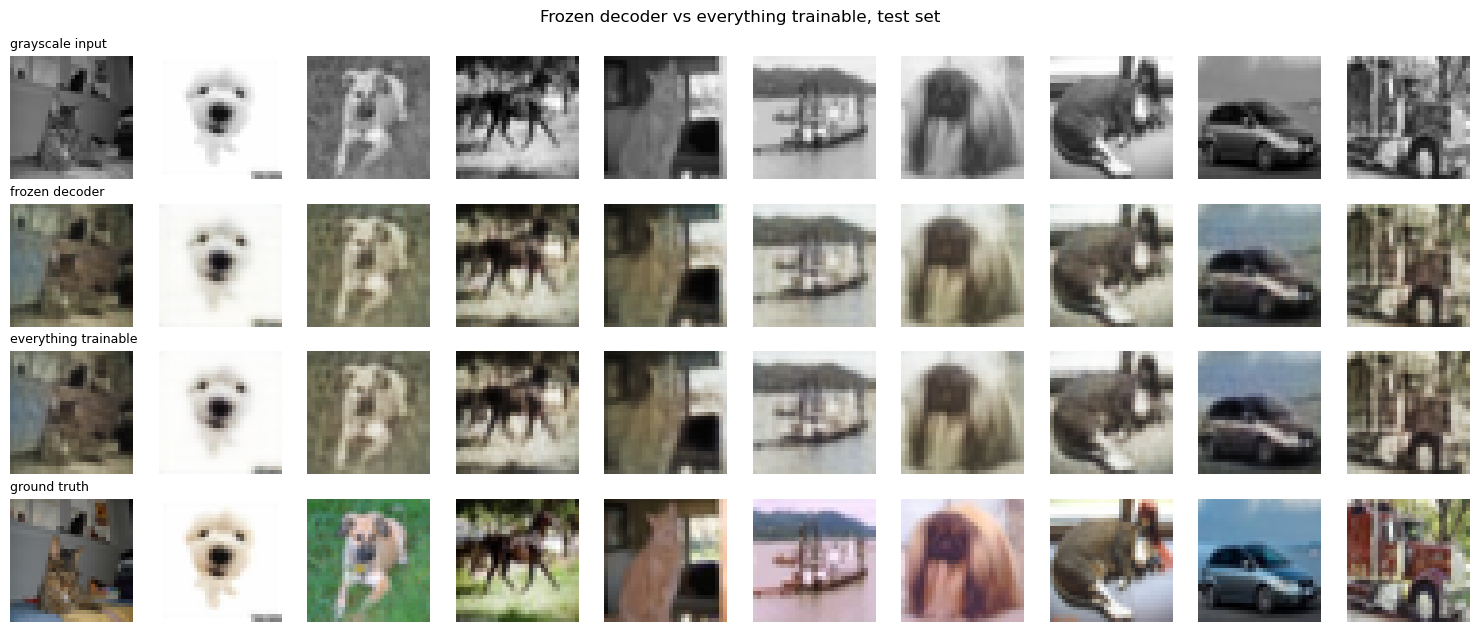

In [40]:
gray_copy = g_test.repeat(1, 3, 1, 1)
gray_pred = predict(gray_model, g_test)
full_pred = predict(full_model, g_test)
idx = torch.arange(16, 26)   # the test images we show

print(f"gray copied to RGB (no colour):    {loss_fn(gray_copy, x_test).item():.5f}")
print(f"gray -> RGB, frozen decoder:       {evaluate(gray_model, gray_test_loader):.5f}")
print(f"gray -> RGB, everything trainable: {evaluate(full_model, gray_test_loader):.5f}")

show_images({"grayscale input": g_test[idx], "frozen decoder": gray_pred[idx],
             "everything trainable": full_pred[idx], "ground truth": x_test[idx]},
            n=10, title="Frozen decoder vs everything trainable, test set")

**Discussion.** Both models beat copying the gray image (0.00607 with the frozen decoder and 0.00592 with everything trainable, against 0.00659), so they learned something about colour, but the gain is small. Unfreezing the decoder helps only a little, and early stopping ends that training after 15 epochs: the frozen decoder was already a good starting point.

From the images we can see the main limitation: the colours are pale and mostly brownish or beige. Some easy cases work, like the blue sky behind the car, but the grass under the dog isn't green and the pink boat stays gray. This is what we expected from the MSE loss. When the colour of an object is uncertain (a car can be red, blue or white), the colour that minimises the MSE is the average of all of them, which is a grayish brown. The dataset also plays a role: CIFAR-10 images are small and the same class comes in many colours, so the network can only learn the colours that are common, like sky and vegetation.

Possible improvements:
- Predict a distribution over colours for every pixel (a classification over colour bins) instead of one value with MSE, so the network doesn't average between possible colours.
- Give the network global information, for example the CIFAR-10 class, so it knows that a frog is green and the sky is blue.
- Work in the Lab colour space and predict only the two colour channels, since the brightness is already in the gray input.

## Conclusion
In this work we built a convolutional autoencoder in PyTorch and used it first to reconstruct CIFAR-10 images and then to colourise grayscale ones.

The baseline from the assignment compresses the image by a factor of 3 (1024 latent values) and reconstructs it with a test MSE of 0.00449. It keeps shapes and main colours but loses the small details.

From the architecture experiments we learned that a bigger latent always lowers the error, but its shape and the capacity of the network matter just as much. A 4x4 latent stays blurry even with 2048 values, while a 16x16 latent reaches almost the same error as a much bigger model with only about 1000 parameters. Wider layers help, and mixing small and big filters in the two path encoder gave the best model (test MSE 0.00115).

For colourisation, we reused the decoder of the best autoencoder and trained a new encoder on gray images, first with the decoder frozen and then with everything trainable. Both beat copying the gray image, but only by a little, and the colours come out pale and brownish. The main limit is the MSE loss, which averages the possible colours of an object, together with the small and varied CIFAR-10 images. A colour classification loss, extra global information such as the image class, or predicting only the colour channels in the Lab space are the most promising next steps.